# 05 Performance in kWh/m³ vor und nach der Begehung

Teil 2: Begehungen und Wirkung

**Worum es geht**
- Kennzahl aus der ÜZ-Folie „Vergleich Gesamteffizienz vor und nach der Optimierung von HAST“: Energie je m³ Heizwasser gegen Außentemperatur, je eine Gerade für unoptimierte und optimierte Stationen.
- Folie: Abstand 2,12 kWh/m³ bzw. 13,4 % bei 8,8 °C, optimierte Gerade flacher.
- Die Kennzahl entspricht der volumenstromgewichteten Spreizung (Vorlauf minus Rücklauf): 1 kWh/m³ ≈ 0,86 K. Hoch ist gut.
- Fragen: Lässt sich der Abstand nachrechnen? Ist er von null unterscheidbar? Zeigt sich die flachere Steigung?

**Daten**
- liest: Stundenreihen aus Notebook 00 über `src/nb00_daten.py`, Außentemperatur über `src/weather.py`, Begehungen über `src/load_begehungen.py`; für die Prüfung in Abschnitt 9 zusätzlich die Rohdateien der Nachlieferungszähler über `src/load_timeseries.py`
- schreibt: `outputs/performance_variante_a.png`, `outputs/performance_variante_b.png` und die Tagesansichten `outputs/performance_variante_a_tage.png`, `outputs/performance_variante_b_tage.png`
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/performance.py`, Tests in `tests/test_performance.py`

## 1 Setup

- Bibliotheken und Projektmodule laden, Ausgabeordner `outputs/` anlegen.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import performance as perf
from src import load_begehungen as lb
from src import nb00_daten as nb00
from src import weather

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (10, 6)

OUTPUTS = Path.cwd().parent / "outputs"
OUTPUTS.mkdir(exist_ok=True)

### 1.1 Parameter

- `MIN_VOLUME_M3`: Mindest-Tagesvolumen (0,5 m³). `BAND`: Plausibilitätsband (−2 bis 70 kWh/m³). `MIN_STUNDEN`: mindestens 20 von 24 gültigen Stundenintervallen je Tag.
- `PUFFER_TAGE`: 7 Tage Einregelphase um die Begehung (Variante B). `STICHTAG_UZ`: Stichtag der Folie, 30.09.2024.
- Wie viele Tage an welcher Bedingung scheitern, zeigt die Filterbilanz in Abschnitt 3.

In [2]:
MIN_VOLUME_M3 = perf.MIN_VOLUME_M3
BAND = perf.BAND_KWH_M3
MIN_STUNDEN = perf.MIN_STUNDEN
PUFFER_TAGE = 7
STICHTAG_UZ = "2024-09-30"


## 2 Daten laden

- Stundenreihen aus Notebook 00 über `src/nb00_daten.py` (93 Zähler). Fünf Zähler reichen bis 20.07.2026, alle anderen bis 11.07.2025. Bei den fünf sind fehlende Zählerstände aus Leistung und Durchfluss integriert.
- Dazu Außentemperatur und Begehungen (58 Begehungen an 56 Zählern). Bei mehreren Begehungen je Station zählt die erste.

In [3]:
serien = nb00.lade_serien()
ladefehler = nb00.nicht_aufbereitet()
hist_von = min(d.index[0].normalize() for d in serien.values() if len(d))
hist_bis = max(d.index[-1].normalize() for d in serien.values() if len(d))

print(f"{len(serien)} Zaehlerreihen aus Notebook 00, "
      f"{len(ladefehler)} dort nicht aufbereitet")
print(f"Historie insgesamt: {hist_von.date()} .. {hist_bis.date()}")

93 Zaehlerreihen aus Notebook 00, 9 dort nicht aufbereitet
Historie insgesamt: 2021-11-01 .. 2026-07-20


In [4]:
t_out = weather.load_outdoor_temperature(hist_von,
                                         hist_bis + pd.Timedelta(hours=23),
                                         allow_download=False)
print(f"Aussentemperatur: {len(t_out)} Stunden, "
      f"{int(t_out['interpolated'].sum())} davon interpoliert")

begehungen = (lb.begehungen_mit_zaehler(available=set(serien))
                .dropna(subset=["meter", "datum"]))
begehungen["meter"] = begehungen["meter"].astype(int)
erste_begehung = begehungen.sort_values("datum").groupby("meter")["datum"].first()

print(f"{len(begehungen)} Begehungen mit Zaehlernummer, "
      f"{begehungen['meter'].nunique()} Zaehler")
display(begehungen["datum"].dt.to_period("M").value_counts().sort_index()
        .rename("Begehungen").to_frame())

Aussentemperatur: 41347 Stunden, 7 davon interpoliert


58 Begehungen mit Zaehlernummer, 56 Zaehler


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


,Begehungen
datum,
2024-08,2
2024-09,34
2024-10,3
2024-11,13
2024-12,1
2025-03,1
2025-09,4


- Der Stichtag der Folie (30.09.2024) passt: 36 der 58 Begehungen liegen davor. Variante A übernimmt ihn.
- Zwei Begehungen im September 2025 haben noch keine Nachher-Phase, landen unter dem festen Stichtag aber trotzdem in „optimiert“. Das ist ein Grund für Variante B.

## 3 Kennzahl aus den Zählerständen

- Tageswerte aus den Differenzen der kumulativen Energie- und Volumenstände: Energie durch Volumen in kWh/m³.
- Verworfen werden Stundenintervalle mit Rücksprung, über Messlücken oder mit unmöglichem Sprung. Der Rest des Tages bleibt.

In [5]:
tab = perf.performance_tabelle(serien, min_volume_m3=MIN_VOLUME_M3,
                               band=BAND, min_stunden=MIN_STUNDEN)
tab = perf.mit_aussentemperatur(tab, t_out)
print(f"{len(tab):,} Stationstage aus {tab['meter'].nunique()} Zaehlern")
display(perf.filterbilanz(tab))

85,986 Stationstage aus 93 Zaehlern


,bedingung,tage,anteil
0,Tagesreihen gesamt,85986,1.000000
1,Volumen unter Schwelle,26414,0.307190
2,ausserhalb Plausibilitaetsband,0,0.000000
3,Abdeckung unter Mindeststunden,16122,0.187496
4,gueltig,59483,0.691775


- 59 483 von 85 986 Stationstagen sind gültig (69 %), aus 93 Zählern.
- 31 % liegen unter der Volumenschwelle (Sommer, Stillstand), 19 % unter der Mindestabdeckung, teils überlappend. Das Plausibilitätsband greift nie.

### 3.1 Gegenprobe gegen die gemessene Spreizung

- Die Kennzahl in Kelvin wird mit der durchflussgewichteten Spreizung aus den Temperaturkanälen verglichen.
- Eine große Abweichung deutet auf ein Geräteproblem.

In [6]:
gegen = tab[tab["gueltig"]].dropna(subset=["dt_abweichung_k"])
print(gegen["dt_abweichung_k"].describe()[["count", "mean", "50%", "std"]])

je_meter = (gegen.groupby("meter")["dt_abweichung_k"]
            .agg(["median", "count"])
            .sort_values("median"))
auffaellig = je_meter[je_meter["median"].abs() > 3.0]
print(f"\nZaehler mit Medianabweichung ueber 3 K: {len(auffaellig)} "
      f"von {len(je_meter)}")
display(auffaellig)

count    57424.000000
mean        -1.257244
50%         -0.508368
std          4.622852
Name: dt_abweichung_k, dtype: float64

Zaehler mit Medianabweichung ueber 3 K: 10 von 93


,median,count
meter,,
53198226,-7.083191,884
68956355,-6.201846,934
68956360,-5.608822,948
72167782,-3.852563,945
72135442,-3.670143,970
72167793,-3.497079,544
72135490,-3.168759,852
80912182,-3.058641,562
80912188,3.359940,551


- Abweichung im Median −0,51 K, Standardabweichung 4,6 K, passend zur stündlichen Abtastung.
- 10 von 93 Zählern weichen im Median um mehr als 3 K ab, einer um mehr als +15 K (58202380). Sie sind Kandidaten für die Fehlerrangliste und bleiben in der Auswertung.

## 4 Zwei Auswertungsvarianten

- Variante A: gemeinsamer Stichtag 30.09.2024 wie auf der Folie.
- Variante B: erstes Begehungsdatum je Station mit ±7 Tagen Puffer, weil die Begehungen über 13 Monate verteilt sind.
- Beide nur mit Stationen, die eine dokumentierte Begehung haben.

In [7]:
basis = tab[tab["gueltig"] & tab["meter"].isin(erste_begehung.index)].copy()
basis = basis.dropna(subset=["t_out_tag"])
print(f"Grundmenge: {len(basis):,} Stationstage, "
      f"{basis['meter'].nunique()} Zaehler")

var_a = perf.gruppe_fester_stichtag(basis, STICHTAG_UZ)
var_b = perf.gruppe_je_station(basis, erste_begehung.to_dict(),
                               puffer_tage=PUFFER_TAGE)
ohne_gruppe = int(var_b["gruppe"].isna().sum())
var_b = var_b.dropna(subset=["gruppe"])

print(f"Variante A: {len(var_a):,} Tage")
print(f"Variante B: {len(var_b):,} Tage, {ohne_gruppe} Tage im Puffer "
      f"von +/- {PUFFER_TAGE} Tagen um die Begehung ausgeblendet")

Grundmenge: 32,116 Stationstage, 51 Zaehler
Variante A: 32,116 Tage
Variante B: 31,632 Tage, 484 Tage im Puffer von +/- 7 Tagen um die Begehung ausgeblendet


- Grundmenge: 32 116 gültige Stationstage an 51 Zählern mit Begehung.
- Variante B blendet 484 Tage im Puffer aus und behält 31 632.

## 5 Regression je Gruppe

- Je Gruppe (unoptimiert, optimiert) eine Gerade: Kennzahl gegen Außentemperatur (Tagesmittel).
- Abstand der beiden Geraden am Bezugspunkt (mittlere Außentemperatur der Daten), dazu ein gemeinsames Modell, das prüft, ob sich die Steigungen unterscheiden.

In [8]:
def auswerten(daten, name):
    """Beide Geraden, Bezugspunkt, Delta und Interaktionstest in einem Schritt."""
    fits = perf.regression_je_gruppe(daten, cluster="meter")
    t_ref = float(pd.to_numeric(daten["t_out_tag"], errors="coerce").mean())
    zeile = fits.set_index("gruppe")
    delta = perf.delta_am_bezugspunkt(
        zeile.loc[perf.GRUPPE_VOR, "steigung"],
        zeile.loc[perf.GRUPPE_VOR, "achsenabschnitt"],
        zeile.loc[perf.GRUPPE_NACH, "steigung"],
        zeile.loc[perf.GRUPPE_NACH, "achsenabschnitt"],
        t_ref)
    modell = perf.interaktionsmodell(daten, cluster="meter")
    delta_ci = perf.delta_aus_interaktion(modell, t_ref)
    print(f"--- {name} --- Bezugspunkt {t_ref:.2f} °C")
    return {"name": name, "daten": daten, "fits": fits, "t_ref": t_ref,
            "delta": delta, "modell": modell, "delta_ci": delta_ci}


erg_a = auswerten(var_a, "Variante A (fester Stichtag)")
erg_b = auswerten(var_b, "Variante B (stationseigenes Begehungsdatum)")

spalten = ["gruppe", "n", "meter", "steigung", "steigung_ci_low",
           "steigung_ci_high", "achsenabschnitt", "r2", "t_out_mittel"]
for erg in (erg_a, erg_b):
    print(f"\n{erg['name']}")
    display(erg["fits"][spalten].round(3))

--- Variante A (fester Stichtag) --- Bezugspunkt 9.66 °C
--- Variante B (stationseigenes Begehungsdatum) --- Bezugspunkt 9.61 °C

Variante A (fester Stichtag)


,gruppe,n,meter,steigung,steigung_ci_low,steigung_ci_high,achsenabschnitt,r2,t_out_mittel
0,unoptimiert,19557,49,-0.716,-0.884,-0.549,29.056,0.196,10.692
1,optimiert,12559,48,-0.640,-0.763,-0.516,29.606,0.154,8.042



Variante B (stationseigenes Begehungsdatum)


,gruppe,n,meter,steigung,steigung_ci_low,steigung_ci_high,achsenabschnitt,r2,t_out_mittel
0,unoptimiert,20166,49,-0.736,-0.926,-0.547,29.361,0.201,10.464
1,optimiert,11466,47,-0.599,-0.713,-0.486,29.216,0.149,8.122


- Konfidenzintervalle sind clusterrobust je Zähler: Sie berücksichtigen, dass Tage derselben Station nicht unabhängig sind. Die Lehrbuchformel unterschätzt die Standardfehler etwa fünf- bis achtfach.
- r² nur 0,15 bis 0,20. Der Großteil der Streuung liegt zwischen den Stationen.

In [9]:
zeilen = []
for erg in (erg_a, erg_b):
    d, m, ci = erg["delta"], erg["modell"], erg["delta_ci"]
    zeilen.append({
        "Variante": erg["name"],
        "t_ref (°C)": erg["t_ref"],
        "y unoptimiert": d["y_vor"],
        "y optimiert": d["y_nach"],
        "Delta (kWh/m³)": d["delta_kwh_m3"],
        "Delta (K)": d["delta_k"],
        "Delta (%)": d["delta_prozent"],
        "Delta KI unten": ci["delta_ci"][0],
        "Delta KI oben": ci["delta_ci"][1],
        "Delta p": ci["delta_p"],
        "Steigungsdiff.": m["steigungsdifferenz"],
        "Steigungsdiff. p": m["steigungsdifferenz_p"],
        "n": m["n"],
        "Stationen": m["n_cluster"],
    })
ergebnis = pd.DataFrame(zeilen)
display(ergebnis.round(4).set_index("Variante").T)

Variante,Variante A (fester Stichtag),Variante B (stationseigenes Begehungsdatum)
t_ref (°C),9.6555,9.6149
y unoptimiert,22.1412,22.2838
y optimiert,23.4303,23.4525
Delta (kWh/m³),1.2890,1.1687
Delta (K),1.1084,1.0049
Delta (%),5.8218,5.2448
Delta KI unten,-0.3942,-0.6755
Delta KI oben,2.9722,3.0130
Delta p,0.1303,0.2089
Steigungsdiff.,0.0766,0.1366


- Abstand am Bezugspunkt: A +1,3 kWh/m³ (KI −0,4 bis 3,0, p ≈ 0,13), B +1,2 kWh/m³ (KI −0,7 bis 3,0, p ≈ 0,21). Die optimierte Gerade liegt höher, der Abstand ist aber nicht von null unterscheidbar.
- Steigungsunterschied A +0,08 (p ≈ 0,26), B +0,14 (p ≈ 0,16): Richtung wie auf der Folie (0,165), aber nicht von null unterscheidbar.

### 5.1 Gegenprobe mit Volumengewichtung

- Die Folie fittet offenbar ungewichtet.
- Eine robuste Aussage darf sich durch Gewichtung mit dem Tagesvolumen nicht umdrehen.

In [10]:
for erg in (erg_a, erg_b):
    gew = perf.regression_je_gruppe(erg["daten"], gewicht="volumen_m3",
                                    cluster="meter")
    print(f"\n{erg['name']} – mit Tagesvolumen gewichtet")
    display(gew[["gruppe", "n", "steigung", "achsenabschnitt", "r2"]].round(3))


Variante A (fester Stichtag) – mit Tagesvolumen gewichtet


,gruppe,n,steigung,achsenabschnitt,r2
0,unoptimiert,19557,-0.826,23.391,0.229
1,optimiert,12559,-0.786,26.829,0.154



Variante B (stationseigenes Begehungsdatum) – mit Tagesvolumen gewichtet


,gruppe,n,steigung,achsenabschnitt,r2
0,unoptimiert,20166,-0.831,23.644,0.225
1,optimiert,11466,-0.782,26.712,0.159


- Der Höhenabstand bleibt und wächst auf rund 3,5 bis 3,8 kWh/m³.
- Die Abflachung wird kleiner: optimiert −0,79 gegen −0,83 (A) und −0,78 gegen −0,83 (B). Sie hängt also an der Gewichtung.

## 6 Decken beide Gruppen denselben Temperaturbereich ab?

- Der Nachher-Winter war laut Notebook 04 rund ein Fünftel kälter.
- Liegen die Temperaturen der Gruppen verschoben, wäre der Wert am Bezugspunkt extrapoliert.

In [11]:
for erg in (erg_a, erg_b):
    print(f"\n{erg['name']}")
    display(perf.temperaturueberdeckung(erg["daten"],
                                        t_ref=erg["t_ref"]).round(2))


Variante A (fester Stichtag)


,gruppe,n,mittel,q05,q25,q50,q75,q95,n_nahe_t_ref,anteil_nahe_t_ref,t_ref_im_bereich
0,unoptimiert,19557,10.69,-1.27,5.91,10.03,16.51,22.24,4447,0.23,True
1,optimiert,12559,8.04,-1.60,2.84,7.03,12.40,21.27,2382,0.19,True



Variante B (stationseigenes Begehungsdatum)


,gruppe,n,mittel,q05,q25,q50,q75,q95,n_nahe_t_ref,anteil_nahe_t_ref,t_ref_im_bereich
0,unoptimiert,20166,10.46,-1.48,5.63,9.78,16.22,22.23,4647,0.23,True
1,optimiert,11466,8.12,-1.60,2.84,7.12,12.51,21.27,2176,0.19,True


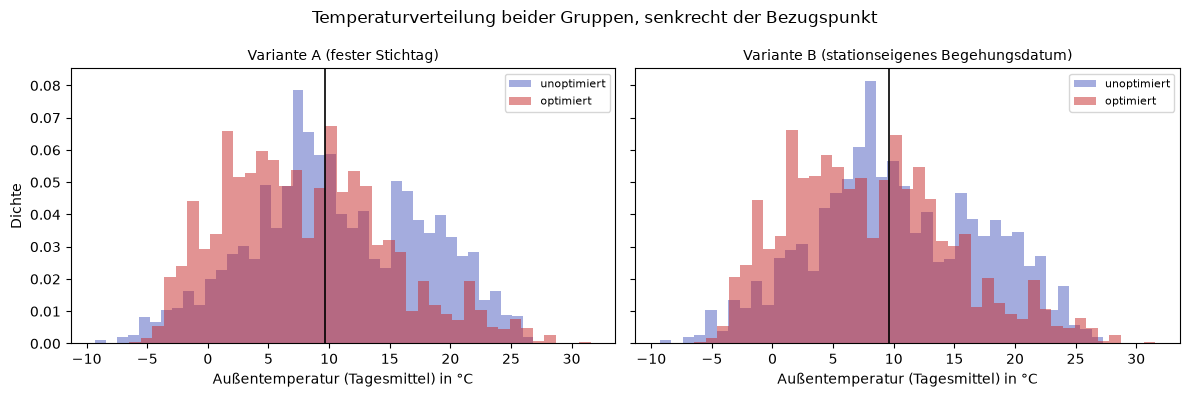

In [12]:
fig, achsen = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, erg in zip(achsen, (erg_a, erg_b)):
    for name, farbe in ((perf.GRUPPE_VOR, "#4b5bbf"),
                        (perf.GRUPPE_NACH, "#c62828")):
        werte = erg["daten"].loc[erg["daten"]["gruppe"] == name, "t_out_tag"]
        ax.hist(werte, bins=40, alpha=0.5, color=farbe, label=name,
                density=True)
    ax.axvline(erg["t_ref"], color="black", linewidth=1.2)
    ax.set_title(erg["name"], fontsize=10)
    ax.set_xlabel("Außentemperatur (Tagesmittel) in °C")
    ax.legend(fontsize=8)
achsen[0].set_ylabel("Dichte")
fig.suptitle("Temperaturverteilung beider Gruppen, senkrecht der Bezugspunkt")
fig.tight_layout()
plt.show()

- Der Bezugspunkt 9,6 bis 9,7 °C ist in beiden Gruppen belegt (je rund 20 % der Tage im Band ±2 K). Es wird nicht extrapoliert.
- „Optimiert“ ist im Mittel 2,7 K (A) bzw. 2,3 K (B) kälter. Für den Abstand ist das unkritisch, für die Steigungen nicht.

## 7 Die Grafik

- Eine Blase je Station, Gruppe und 2-K-Temperaturklasse: Höhe = Energie durch Volumen, Fläche = Volumen. Die Geraden stammen aus dem Fit über die Tageswerte.
- Darunter die Tagesebene, damit die Streuung sichtbar bleibt.

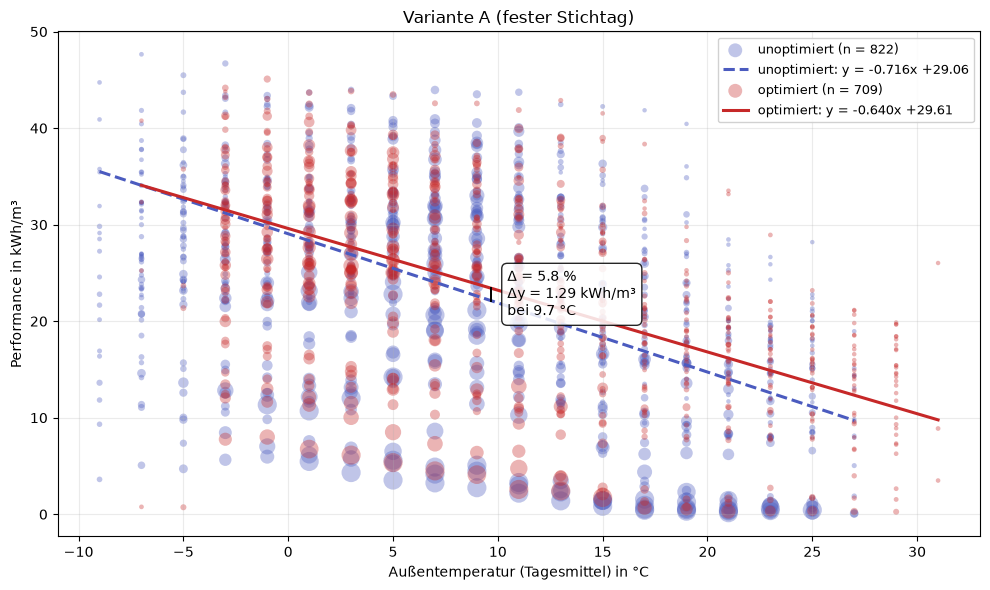

1531 Blasen aus 32,116 Stationstagen -> outputs/performance_variante_a.png


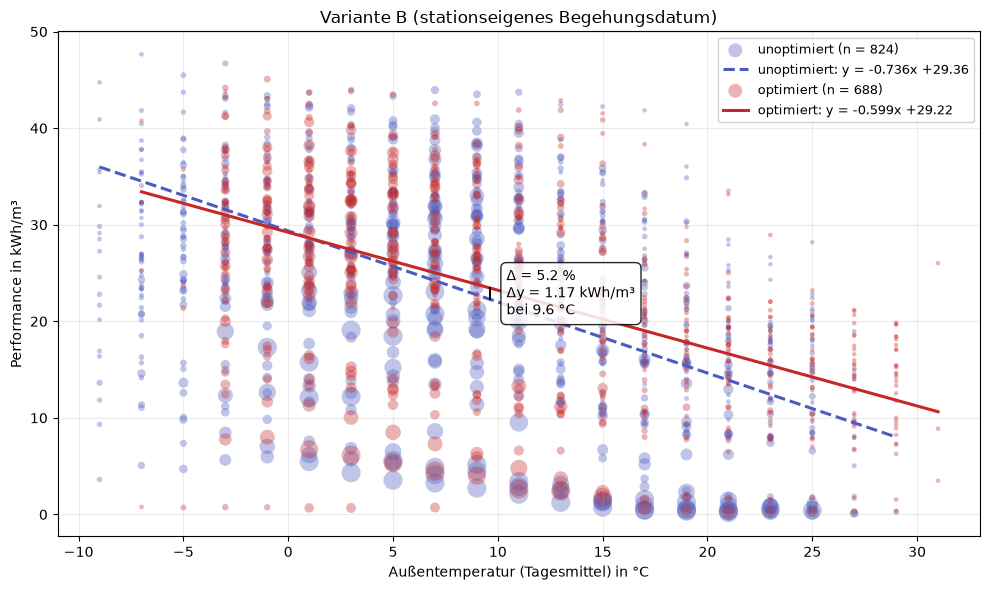

1512 Blasen aus 31,632 Stationstagen -> outputs/performance_variante_b.png


In [13]:
KLASSENBREITE = 2.0

for erg, datei in ((erg_a, "performance_variante_a.png"),
                   (erg_b, "performance_variante_b.png")):
    blasen = perf.blasen_aggregat(erg["daten"], klassenbreite=KLASSENBREITE)
    fig, ax = plt.subplots(figsize=(10, 6))
    perf.blasendiagramm(blasen, erg["fits"], erg["t_ref"],
                        delta=erg["delta"], titel=erg["name"], ax=ax)
    fig.tight_layout()
    fig.savefig(OUTPUTS / datei, dpi=150)
    plt.show()
    print(f"{len(blasen)} Blasen aus {len(erg['daten']):,} Stationstagen "
          f"-> outputs/{datei}")

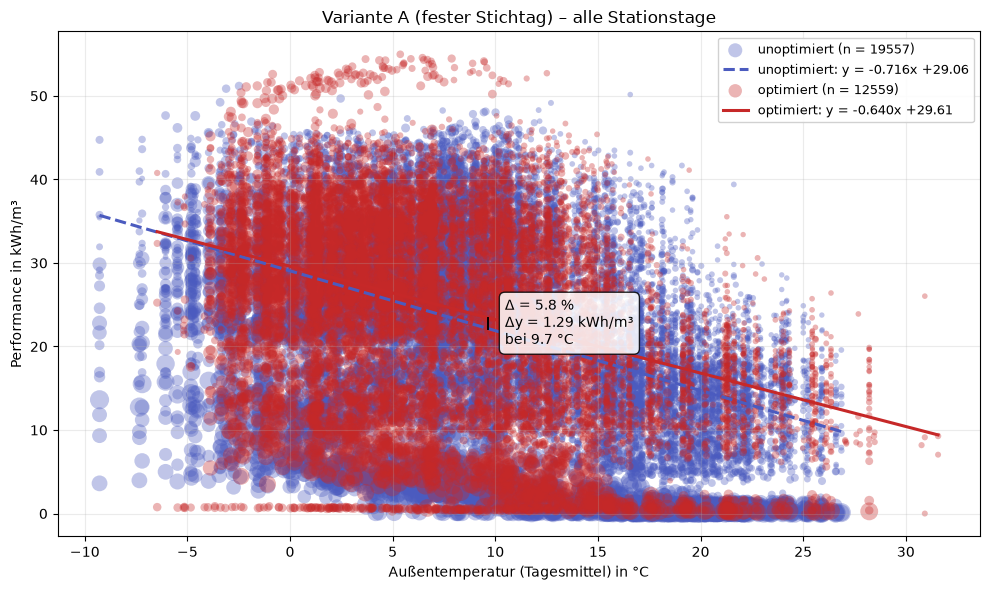

gespeichert: outputs/performance_variante_a_tage.png


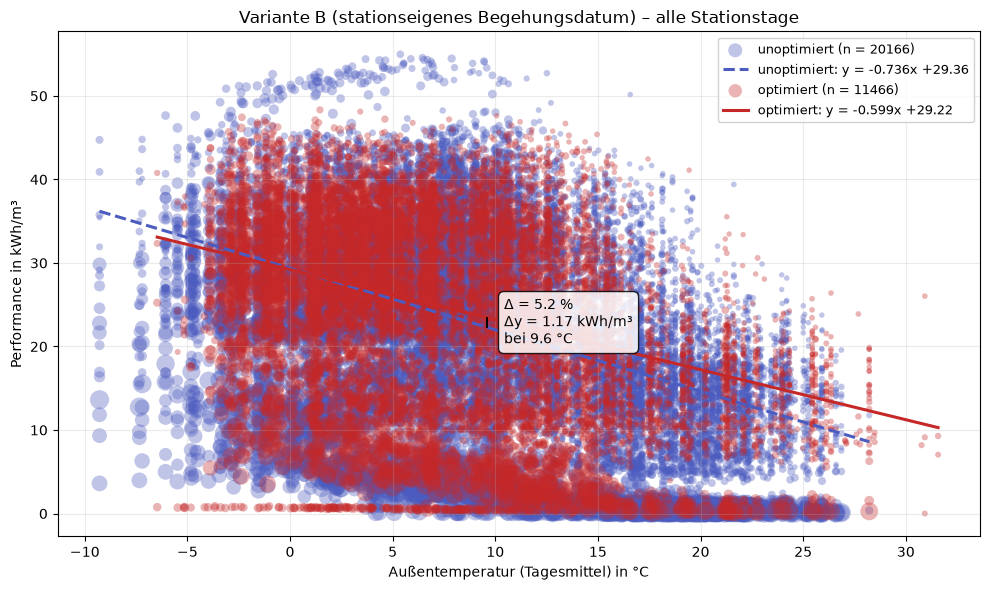

gespeichert: outputs/performance_variante_b_tage.png


In [14]:
#Gegenprobe ohne Verdichtung: dieselben Geraden auf allen Tageswerten
for erg, datei in ((erg_a, "performance_variante_a_tage.png"),
                   (erg_b, "performance_variante_b_tage.png")):
    fig, ax = plt.subplots(figsize=(10, 6))
    perf.blasendiagramm(erg["daten"], erg["fits"], erg["t_ref"],
                        delta=erg["delta"],
                        titel=f"{erg['name']} – alle Stationstage", ax=ax)
    fig.tight_layout()
    fig.savefig(OUTPUTS / datei, dpi=150)
    plt.show()
    print(f"gespeichert: outputs/{datei}")

## 8 Vergleich mit den Zahlen der ÜZ

- Die Zahlen der Folie direkt neben beiden Varianten, mit Bezugspunkt.

In [15]:
vergleich = pd.DataFrame({
    "Kennzahl": ["Steigung unoptimiert", "Steigung optimiert",
                 "Achsenabschnitt unoptimiert", "Achsenabschnitt optimiert",
                 "Bezugspunkt (°C)", "Delta (kWh/m³)", "Delta (%)",
                 "Stationen", "Beobachtungen"],
    "ÜZ (Folie)": [-0.588, -0.423, 21.10, 21.77, 8.8, 2.12, 13.4,
                   "rund 60", "unbekannt"],
})
for erg, spalte in ((erg_a, "Variante A"), (erg_b, "Variante B")):
    z = erg["fits"].set_index("gruppe")
    vergleich[spalte] = [
        round(z.loc[perf.GRUPPE_VOR, "steigung"], 3),
        round(z.loc[perf.GRUPPE_NACH, "steigung"], 3),
        round(z.loc[perf.GRUPPE_VOR, "achsenabschnitt"], 2),
        round(z.loc[perf.GRUPPE_NACH, "achsenabschnitt"], 2),
        round(erg["t_ref"], 1),
        round(erg["delta"]["delta_kwh_m3"], 2),
        round(erg["delta"]["delta_prozent"], 1),
        int(erg["modell"]["n_cluster"]),
        int(erg["modell"]["n"]),
    ]
display(vergleich.set_index("Kennzahl"))

,ÜZ (Folie),Variante A,Variante B
Kennzahl,,,
Steigung unoptimiert,-0.588,-0.716,-0.736
Steigung optimiert,-0.423,-0.640,-0.599
Achsenabschnitt unoptimiert,21.1,29.060,29.360
Achsenabschnitt optimiert,21.77,29.610,29.220
Bezugspunkt (°C),8.8,9.700,9.600
Delta (kWh/m³),2.12,1.290,1.170
Delta (%),13.4,5.800,5.200
Stationen,rund 60,51.000,51.000
Beobachtungen,unbekannt,32116.000,31632.000


- Abstand 1,3 bzw. 1,2 kWh/m³ (Folie 2,12), relativ 5,8 % bzw. 5,2 % (Folie 13,4 %), Bezugspunkt 9,7 bzw. 9,6 statt 8,8 °C.
- Steigungsabstand 0,08 bzw. 0,14 (Folie 0,165).
- Das absolute Niveau ist höher: unoptimiert 22,1 gegen 15,9 kWh/m³. Die Ursache ist nicht klärbar, für den Gruppenvergleich aber unerheblich.
- Folie: rund 60 optimierte HAST im ganzen Versorgungsgebiet, hier 51 Zähler in Wiesentheid. Die Volumenschwelle der ÜZ ist nicht bekannt.

In [16]:
#Gegenprobe zum Zeitraum: wie verteilt sich die Nachher-Phase auf die Jahre
nach = var_b[var_b["gruppe"] == perf.GRUPPE_NACH]
display(nach.groupby(pd.DatetimeIndex(nach["datum"]).to_period("Q"))
        .agg(tage=("performance", "size"),
             zaehler=("meter", "nunique"),
             t_out_mittel=("t_out_tag", "mean")).round(1))

,tage,zaehler,t_out_mittel
datum,,,
2024Q3,179,25,13.7
2024Q4,3140,43,6.0
2025Q1,3855,44,3.6
2025Q2,3047,44,14.5
2025Q3,364,35,20.0
2025Q4,308,4,5.2
2026Q1,333,4,3.5
2026Q2,206,4,14.7
2026Q3,34,3,22.6


## 9 Nachlieferung bis Juli 2026 (fünf Zähler)

- Ab dem vierten Quartal 2025 tragen nur drei bis vier Nachlieferungszähler die Nachher-Phase (881 Tage, Tabelle oben).
- Ihre Energie- und Volumenstände sind ab 26.05.2024 aus Leistung und Durchfluss integriert.
- Geprüft werden die Integration und ihre Wirkung auf Variante B.

In [17]:
ODS_METER = nb00.lange_reihen(serien)
GRENZE_ODS = pd.Timestamp("2024-05-27")   #ab hier nur noch integrierte Stände

#Zählerstände der Rohdatei nur zum Prüfen, ausgewertet wird weiter auf NB 00
from src import load_timeseries as lts

zeilen = []
for zid in ODS_METER:
    csv = (lts.load_meter_timeseries(zid).rename(columns=nb00.SPALTEN_MAP)
           .set_index("Timestamp").sort_index())
    csv.index = csv.index.floor("h")
    csv = csv[~csv.index.duplicated(keep="last")]
    d = serien[zid]
    d = d[d.index <= csv.index[-1]]
    #alles außer dem ersten Stand integrieren, auch wo NB 00 misst
    ohne = d.copy()
    ohne.iloc[1:, ohne.columns.get_indexer(["energy", "volume"])] = np.nan
    a = perf.tagesperformance(csv)
    b = perf.tagesperformance(nb00.zaehlerstaende_integrieren(ohne))
    m = a.merge(b, on="datum", suffixes=("_mess", "_int"))
    m = m[m["gueltig_mess"] & m["gueltig_int"]]
    m["zeitraum"] = np.where(m["datum"] >= GRENZE_ODS,
                             "ab 27.05.2024", "bis 26.05.2024")
    for zr, t in m.groupby("zeitraum"):
        dd = t["performance_int"] - t["performance_mess"]
        zeilen.append({
            "meter": zid, "zeitraum": zr, "tage": len(t),
            "median_abw": dd.median(),
            "median_abw_prozent": 100 * (dd / t["performance_mess"]).median(),
            "p05": dd.quantile(0.05), "p95": dd.quantile(0.95),
            "korrelation": t["performance_int"].corr(t["performance_mess"]),
        })
display(pd.DataFrame(zeilen).round(3))

,meter,zeitraum,tage,median_abw,median_abw_prozent,p05,p95,korrelation
0,68956347,ab 27.05.2024,261,-0.808,-2.646,-6.887,6.981,0.898
1,68956347,bis 26.05.2024,415,-0.459,-1.416,-7.714,4.973,0.901
2,68956371,ab 27.05.2024,114,-0.023,-0.060,-3.030,2.645,0.856
3,68956371,bis 26.05.2024,110,-5.901,-21.859,-11.376,1.037,0.876
4,68956372,ab 27.05.2024,410,-0.091,-0.817,-0.927,1.213,0.997
5,68956372,bis 26.05.2024,561,-0.137,-1.954,-3.955,3.126,0.981
6,72167783,ab 27.05.2024,338,-0.042,-0.137,-0.423,0.504,1.000
7,72167783,bis 26.05.2024,514,0.038,1.005,-1.687,2.067,0.994
8,80912172,ab 27.05.2024,212,0.478,2.052,-4.166,4.491,0.768
9,80912172,bis 26.05.2024,163,0.212,0.882,-3.175,3.330,0.793


- Gegen gemessene Zählerstände: Median-Abweichung −2,6 bis +2,1 %, Korrelation 0,77 bis 1,00. Ausnahme ist 68956371 mit −22 % auf 110 Tagen.
- Das Niveau über Monate ist brauchbar, einzelne Tage nicht (p05/p95 bis etwa ±7 kWh/m³).
- Für 2025/26 gibt es keine Referenz, die Zahlen dort sind unsicherer.

In [18]:
beg_ods = {z: d for z, d in erste_begehung.items() if z in ODS_METER}
print(f"{len(beg_ods)} der {len(ODS_METER)} Zaehler haben eine Begehung")
ende_gemeinsam = max(d.index[-1] for z, d in serien.items()
                     if z not in ODS_METER)

zeilen, fits = [], []
for stand in ("bis 11.07.2025", "bis Juli 2026"):
    serien_ods = {z: serien[z] for z in beg_ods}
    if stand == "bis 11.07.2025":
        serien_ods = {z: d[d.index <= ende_gemeinsam]
                      for z, d in serien_ods.items()}
    t = perf.mit_aussentemperatur(perf.performance_tabelle(serien_ods), t_out)
    t = t[t["gueltig"]].dropna(subset=["t_out_tag"])
    g = perf.gruppe_je_station(t, beg_ods, puffer_tage=PUFFER_TAGE)
    g = g.dropna(subset=["gruppe"])
    for name, teil in g.groupby("gruppe"):
        zeilen.append({
            "stand": stand, "gruppe": name, "tage": len(teil),
            "zaehler": teil["meter"].nunique(),
            "performance_median": teil["performance"].median(),
            "t_out_mittel": teil["t_out_tag"].mean(),
            "letzter_tag": teil["datum"].max(),
        })
    #nur vier Zähler, zu wenig für robuste Standardfehler
    fits.append(perf.regression_je_gruppe(g, cluster=None).assign(stand=stand))

gruppen = pd.DataFrame(zeilen)
display(gruppen.assign(letzter_tag=gruppen["letzter_tag"].dt.date).round(2))
schieflage = (gruppen.pivot(index="stand", columns="gruppe",
                            values="t_out_mittel")
              .assign(schieflage_k=lambda x: x["optimiert"]
                      - x["unoptimiert"]))
display(schieflage.round(2))
display(pd.concat(fits)[["stand", "gruppe", "n", "steigung",
                         "achsenabschnitt", "r2"]].round(3))


4 der 5 Zaehler haben eine Begehung


,stand,gruppe,tage,zaehler,performance_median,t_out_mittel,letzter_tag
0,bis 11.07.2025,optimiert,474,2,21.36,7.71,2025-07-10
1,bis 11.07.2025,unoptimiert,1977,4,11.34,10.23,2025-07-10
2,bis Juli 2026,optimiert,1455,4,18.82,8.20,2026-07-19
3,bis Juli 2026,unoptimiert,1985,4,11.11,10.27,2025-07-18


gruppe,optimiert,unoptimiert,schieflage_k
stand,,,
bis 11.07.2025,7.71,10.23,-2.52
bis Juli 2026,8.20,10.27,-2.07


,stand,gruppe,n,steigung,achsenabschnitt,r2
0,bis 11.07.2025,unoptimiert,1977,-1.251,29.359,0.332
1,bis 11.07.2025,optimiert,474,-0.492,23.454,0.366
0,bis Juli 2026,unoptimiert,1985,-1.253,29.369,0.335
1,bis Juli 2026,optimiert,1455,-0.450,21.213,0.107


- 4 der 5 Zähler haben eine Begehung. Die Nachher-Tage steigen durch die Nachlieferung von 474 auf 1455.
- Der Median in „optimiert“ sinkt von 21,4 auf 18,8 kWh/m³, vor allem durch 72167783 mit kaum Wärmeabnahme im Winter 2025/26.
- Vier Stationen, eine davon dominiert: keine Aussage zur Wirkung.

## Zusammenfassung & Bewertung

**Ergebnis**
- Gleiche Richtung wie auf der Folie, aber kleiner: nach der Begehung 1,2 bis 1,3 kWh/m³ mehr, etwa 1,0 bis 1,1 K mehr Spreizung, 5,2 bis 5,8 % (Folie 13,4 %).

**Belastbar**
- Der Abstand ist in beiden Varianten positiv und bleibt bei Volumengewichtung (3,5 bis 3,8 kWh/m³). Der Bezugspunkt ist dicht belegt.
- Die Kennzahl stimmt im Median auf rund 0,5 K mit der gemessenen Spreizung überein.

**Schwach**
- Mit clusterrobusten Fehlern ist der Abstand nicht von null unterscheidbar (A p ≈ 0,13, B p ≈ 0,21).
- Die flachere optimierte Gerade ist nur angedeutet (p ≈ 0,16 bis 0,26) und bei Gewichtung kleiner.
- Keine Kontrollgruppe; „optimiert“ ist im Mittel 2,3 bis 2,7 K kälter.
- Die Nachher-Phase ab Ende 2025 stammt nur aus integrierten Nachlieferungsdaten.
- Das absolute Niveau liegt rund 6 kWh/m³ über der Folie, Ursache ungeklärt.

**Offen**
- Kontrollgruppe und Wintervergleich aus Notebook 04 übertragen.
- Begehungen vom September 2025 ohne Nachher-Phase aus Variante A nehmen?
- 10 von 93 Zählern mit über 3 K Abweichung ausschließen oder als Befund führen?